# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 1 GO / Gate 2 GO / Gate 3 NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional expression
notebook follows signatures directly.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus). Per the **derive-don't-inherit** mandate
we do not inherit that pair: we score a candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors
**plus the mesenchymal / neural-crest FOXC and PRRX factors** (evaluation/testing lesson), **excluding
VIM** (a mesenchymal *marker*, not a transcription factor) — along *this* trajectory (the somitogenesis
body-axis, rooted at the Gast/pSom-high developmental origin) and let the data choose the most
end-specific factor at each end, gated on detectable expression. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
name = os.path.basename(os.getcwd())                     # 'Qian2020_Breast-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))    # 'Breast'
dataname = re.sub(r'-\d+$', '', name)                    # 'Qian2020_Breast' (raw data has no -1 suffix)
pth  = os.path.join(*([os.pardir]*4))                    # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dataname)
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)   # h5ads (-1)
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)  # figs (-1)
pth_cb   = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
sys.path.append(os.path.join(pth, 'mesencontext'))
print('dataset:', name, '| category:', cat)
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
from scipy.stats import spearmanr

dataset: Qian2020_Breast-1 | category: Breast


### Load the rooted, signature-scored manifold

In [2]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 4801 | pseudotime range 0.0 -> 12.15


### Derive the end-specific EMT-TFs (data-driven)
For each candidate TF: fraction of cells expressing it, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. Most negative correlation
(sufficiently expressed) marks the root end; most positive marks the terminus. Factors below a 3 %
expression floor are too sparse to overlay honestly.

In [3]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']  # VIM excluded (marker, not TF)
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j, g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho, p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 SNAI2      0.114       0.465      0.000    -0.483    EARLY(root)
 FOXC1      0.104       0.141      0.001    -0.425    EARLY(root)
TWIST2      0.030       0.028      0.000    -0.236    EARLY(root)
 FOXC2      0.023       0.019      0.000    -0.197    EARLY(root)
 PRRX1      0.026       0.035      0.000    -0.186    EARLY(root)
 PRRX2      0.019       0.015      0.000    -0.175    EARLY(root)
  ZEB1      0.012       0.009      0.000    -0.132    EARLY(root)
TWIST1      0.008       0.007      0.000    -0.100    EARLY(root)
  ZEB2      0.005       0.005      0.001    -0.053    EARLY(root)
 SNAI1      0.068       0.018      0.034     0.004 LATE(terminus)

derived pair: SNAI2 (early/root) <-> SNAI1 (late/terminus)


### EMT-TF expression overlay (deliverable)
House style: `figsize=(3.5,1.5)`, developmental origin left→right, `size=30`. Each factor is
thresholded at the upper quartile of expression among its expressing cells and drawn as a
**categorical** overlay (thresholded expressers coloured over the grey manifold — the reference
style, *not* a continuous single-gene colormap). The abundant marker is drawn first so the sparser
one reads on top.

overlay thresholds (upper quartile among expressers): {'SNAI2': 1.903, 'SNAI1': 0.621} | cells shown: {'SNAI2': 137, 'SNAI1': 82}
SNAI2: 11.4% expressing; 137 shown (upper quartile), mean pseudotime of shown cells = 0.01 (all cells = 0.49)
SNAI1: 6.8% expressing; 82 shown (upper quartile), mean pseudotime of shown cells = 0.66 (all cells = 0.49)
shown-cell pseudotime separation (SNAI2 vs SNAI1) = 0.65
saved expression.pdf


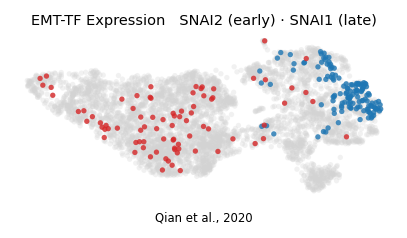

In [4]:
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def _vec(g):
    x = adata[:, g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5, -.14, 'Qian et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = abs(tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean())
print(f'shown-cell pseudotime separation ({early_tf} vs {late_tf}) = {sep:.2f}')
print('saved expression.pdf')